# ML Assignment 2 – Classification on UCI Adult Income

## AVISEK BANIK 
## BITS ID : 2026CT05186
Five models (Logistic Regression, Decision Tree, kNN, Gaussian Naive Bayes, Random Forest) on one dataset, evaluated with Accuracy, AUC, Precision, Recall, F1 and MCC.

In [1]:
import os, warnings, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, matthews_corrcoef,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
warnings.filterwarnings("ignore")

SEED = 42
for d in ("model", "outputs", "data"):
    os.makedirs(d, exist_ok=True)

print(' Import Successful')

 Import Successful


## Step 1 – Dataset
**UCI Adult (Census Income)**: 14 features, ~32.5K rows, missing values (`?`), duplicates, imbalanced binary target (`income` > 50K = 1). Chosen because it satisfies every requirement (≥12 features, ≥1,000 rows, missing values, class imbalance).

In [2]:
COLUMNS = ["age","workclass","fnlwgt","education","education_num","marital_status","occupation",
           "relationship","race","sex","capital_gain","capital_loss","hours_per_week","native_country","income"]
URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
LOCAL = "data/adult.csv"
if os.path.exists(LOCAL):
    df = pd.read_csv(LOCAL)
else:
    df = pd.read_csv(URL, header=None, names=COLUMNS, skipinitialspace=True, na_values="?")
    df.to_csv(LOCAL, index=False)
df.columns = COLUMNS
df = df.replace("?", np.nan)
df["income"] = (df["income"].astype(str).str.strip().str.rstrip(".") == ">50K").astype(int)
print(df.shape)
df.head()

(32561, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,0
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,0
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,0
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,0
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,0


str      8
int64    7
Name: count, dtype: int64 

Missing values:
 workclass         1836
occupation        1843
native_country     583
dtype: int64 

Duplicate rows: 24

 income
0    24720
1     7841
Name: count, dtype: int64 
 income
0    75.92
1    24.08
Name: count, dtype: float64


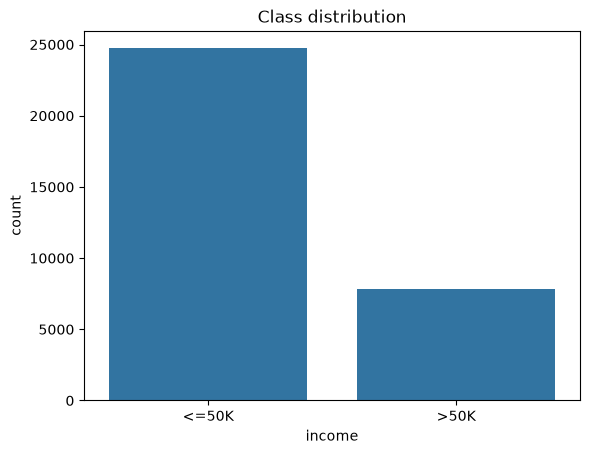

In [3]:
print(df.dtypes.value_counts(), "\n")
print("Missing values:\n", df.isna().sum()[df.isna().sum() > 0], "\n")
print("Duplicate rows:", df.duplicated().sum())
dist = df["income"].value_counts()
print("\n", dist, "\n", (dist / len(df) * 100).round(2))
sns.countplot(x="income", data=df)
plt.xticks([0, 1], ["<=50K", ">50K"]); plt.title("Class distribution")
plt.savefig("outputs/class_distribution.png", dpi=150); plt.show()

## Step 2 – Preprocessing
Duplicates dropped, 80:20 stratified split with a fixed seed, and imputation / encoding / scaling placed inside a `Pipeline` so they are fitted on training data only.

In [4]:
df = df.drop_duplicates().reset_index(drop=True)
X, y = df.drop(columns="income"), df["income"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Positive ratio  train: %.4f  test: %.4f" % (y_train.mean(), y_test.mean()))
pd.concat([X_test, y_test], axis=1).to_csv("test_data.csv", index=False)

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()

def make_prep():
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("sc", StandardScaler())]), num_cols),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols)])

Train: (26029, 14) Test: (6508, 14)
Positive ratio  train: 0.2409  test: 0.2409


## Step 3 – Models and evaluation

In [5]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, random_state=SEED),
    "kNN": KNeighborsClassifier(n_neighbors=15, n_jobs=-1),
    "Naive Bayes": GaussianNB(),
    "Random Forest (Ensemble)": RandomForestClassifier(n_estimators=200, min_samples_leaf=2,
                                                       n_jobs=-1, random_state=SEED),
}
results, roc_data, cms = {}, {}, {}
for name, clf in models.items():
    pipe = Pipeline([("prep", make_prep()), ("model", clf)]).fit(X_train, y_train)
    pred, prob = pipe.predict(X_test), pipe.predict_proba(X_test)[:, 1]
    results[name] = {"Accuracy": accuracy_score(y_test, pred), "AUC": roc_auc_score(y_test, prob),
                     "Precision": precision_score(y_test, pred), "Recall": recall_score(y_test, pred),
                     "F1": f1_score(y_test, pred), "MCC": matthews_corrcoef(y_test, pred)}
    roc_data[name] = roc_curve(y_test, prob)[:2]
    cms[name] = confusion_matrix(y_test, pred)
    joblib.dump(pipe, "model/" + name.split(" (")[0].lower().replace(" ", "_") + ".joblib")
res = pd.DataFrame(results).T.round(4)
res.index.name = "ML Model Name"
res.to_csv("outputs/metrics.csv")
res

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.8569,0.9099,0.7437,0.6199,0.6762,0.5893
Decision Tree,0.8629,0.9103,0.8062,0.5676,0.6662,0.5974
kNN,0.8459,0.8903,0.7016,0.6269,0.6622,0.5643
Naive Bayes,0.5361,0.7492,0.3369,0.9560,0.4983,0.3300
Random Forest (Ensemble),0.8714,0.9222,0.7840,0.6435,0.7068,0.6305


In [6]:
print(res.reset_index().to_markdown(index=False))   # paste this table into the README
print("\nBest model by MCC:", res["MCC"].idxmax())

| ML Model Name            |   Accuracy |    AUC |   Precision |   Recall |     F1 |    MCC |
|:-------------------------|-----------:|-------:|------------:|---------:|-------:|-------:|
| Logistic Regression      |     0.8569 | 0.9099 |      0.7437 |   0.6199 | 0.6762 | 0.5893 |
| Decision Tree            |     0.8629 | 0.9103 |      0.8062 |   0.5676 | 0.6662 | 0.5974 |
| kNN                      |     0.8459 | 0.8903 |      0.7016 |   0.6269 | 0.6622 | 0.5643 |
| Naive Bayes              |     0.5361 | 0.7492 |      0.3369 |   0.956  | 0.4983 | 0.33   |
| Random Forest (Ensemble) |     0.8714 | 0.9222 |      0.784  |   0.6435 | 0.7068 | 0.6305 |

Best model by MCC: Random Forest (Ensemble)


## Visualisations

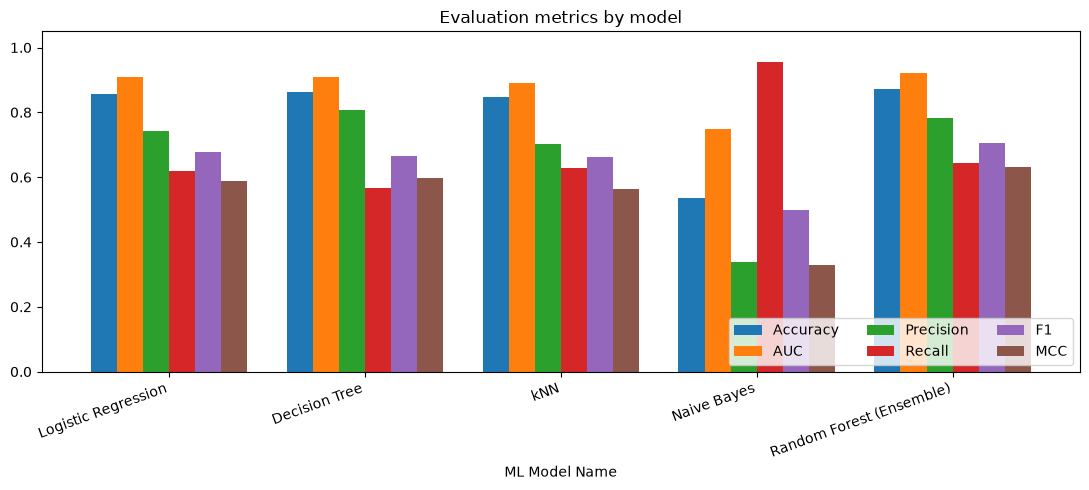

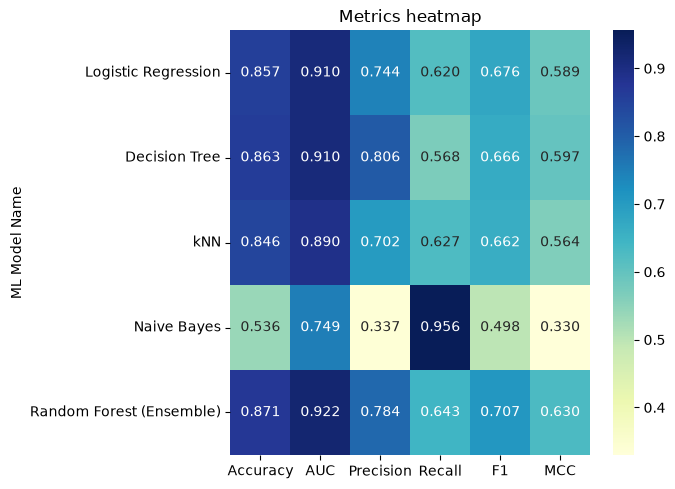

In [7]:
ax = res.plot(kind="bar", figsize=(11, 5), width=0.8)
ax.set_ylim(0, 1.05); ax.set_title("Evaluation metrics by model")
plt.xticks(rotation=20, ha="right"); plt.legend(loc="lower right", ncol=3)
plt.tight_layout(); plt.savefig("outputs/metrics_comparison.png", dpi=150); plt.show()

plt.figure(figsize=(7, 5))
sns.heatmap(res, annot=True, fmt=".3f", cmap="YlGnBu"); plt.title("Metrics heatmap")
plt.tight_layout(); plt.savefig("outputs/metrics_heatmap.png", dpi=150); plt.show()

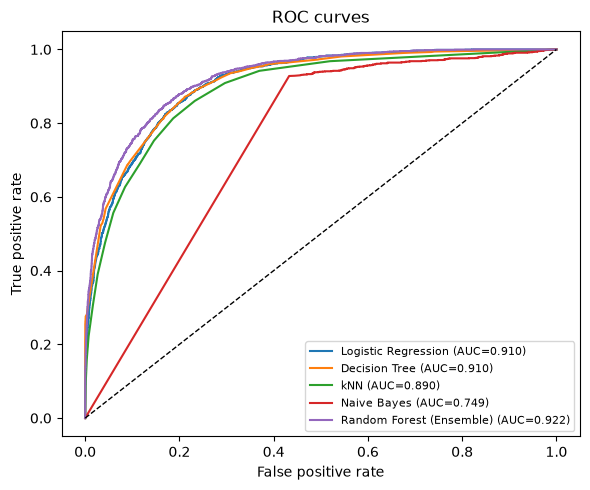

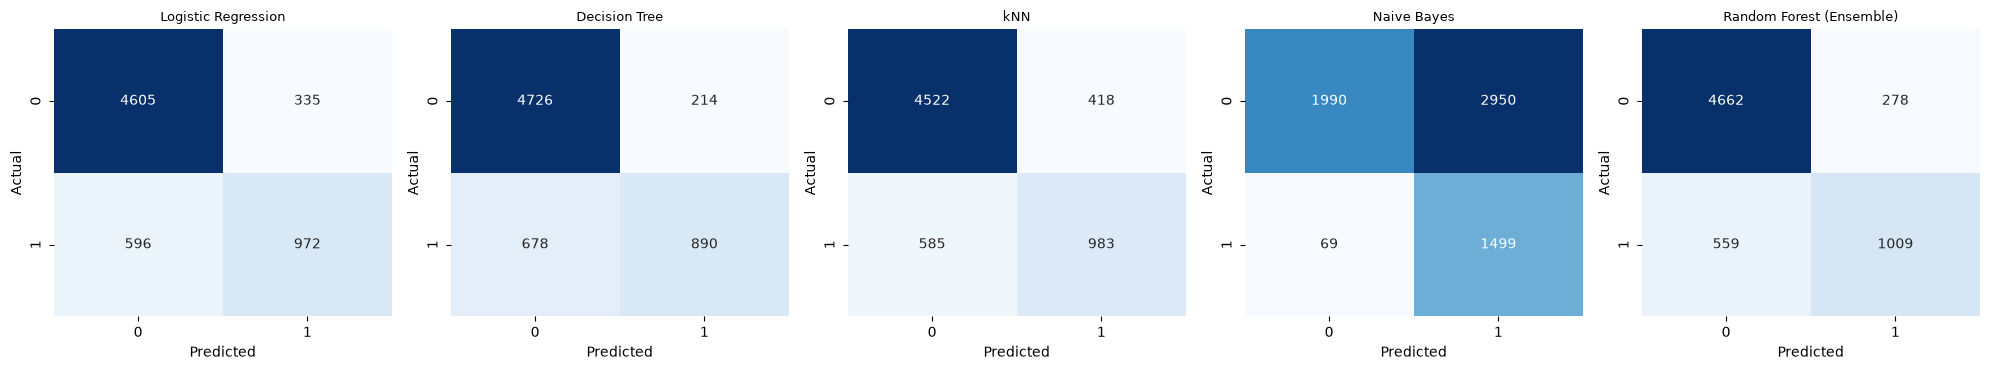

In [8]:
plt.figure(figsize=(6, 5))
for n, (fpr, tpr) in roc_data.items():
    plt.plot(fpr, tpr, label=f"{n} (AUC={res.loc[n, 'AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves"); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig("outputs/roc_curves.png", dpi=150); plt.show()

fig, axes = plt.subplots(1, 5, figsize=(20, 3.8))
for a, (n, cm) in zip(axes, cms.items()):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=a)
    a.set_title(n, fontsize=9); a.set_xlabel("Predicted"); a.set_ylabel("Actual")
plt.tight_layout(); plt.savefig("outputs/confusion_matrices.png", dpi=150); plt.show()

## Observations

| ML Model Name | Observation about model performance |
|---|---|
| Logistic Regression | Solid linear baseline (Accuracy 0.8569, AUC 0.9099, MCC 0.5893). Recall of 0.6199 means about 38% of high-income people (>50K) are missed, which is expected with a 24% minority class. |
| Decision Tree | Highest precision of all models (0.8062) but the lowest recall among the well-behaved models (0.5676), so it predicts >50K cautiously. Its AUC (0.9103) matches Logistic Regression, showing the depth-limited tree generalises well while staying interpretable. |
| kNN | Weakest of the four well-behaved models (Accuracy 0.8459, AUC 0.8903, MCC 0.5643). Distances become less informative in the high-dimensional one-hot encoded space, and kNN is also the slowest at prediction time. |
| Naive Bayes | Clearly the worst: Accuracy 0.5361 is below the ~75.9% a majority-class guess would achieve. It labels most people as >50K (Recall 0.9560 but Precision only 0.3369, MCC 0.3300). The Gaussian and feature-independence assumptions do not hold for one-hot encoded, correlated census features. |
| Random Forest (Ensemble) | Best overall: highest Accuracy (0.8714), AUC (0.9222), F1 (0.7068) and MCC (0.6305). Averaging 200 trees captures non-linear relationships and feature interactions while reducing the variance of a single tree. |
| **Overall Winner for this dataset** | **Random Forest (Ensemble)** - it leads on MCC, AUC, F1 and Accuracy, giving the best balance between precision and recall on an imbalanced target. Decision Tree and Logistic Regression are close runners-up; Naive Bayes is unsuitable for this dataset. |

**Note on imbalance:** about 76% of records are <=50K, so accuracy alone is misleading. MCC, F1 and AUC give a fairer comparison, and all three rank Random Forest first.